# Intermittent background

We simulate a small synthetic population, score each segment, compute the normalization $\varepsilon_N$, form $\Lambda^\star=\Lambda+\varepsilon_N$, and infer the merger rate with and without the correction. The cluster-scale version lives in `scripts/sgwb/`.

In [1]:
import sys, pathlib, time
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT/'src')); sys.path.insert(0, str(ROOT/'examples'))
import numpy as np, matplotlib.pyplot as plt, healpy as hp
from scipy.special import gammainc
from tqdm import tqdm
from exmarg import figstyle, make_event
from exmarg.data import make_data
from exmarg.evaluate import zeta, mc_q_to_m1m2
from exmarg.kernel import load_sumstore, sum_lnlam_pair
from exmarg.profiles import profile
from exmarg.detectors import S
from exmarg.tables import _quad, _responses
from fetch_tables import ensure_nodes
figstyle.apply()
get_ipython().run_line_magic("matplotlib","inline")
NAVY, RED = figstyle.NAVY, figstyle.RED

/projects/standard/vuk/shared/boyb001/non_gaussian/exmarg/src/exmarg/profiles.py:14: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


## 1. Setup

In [2]:
T_SEG, FMIN, FMAX, N_MAX = 4.0, 25.0, 512.0, 120
TC, DT = T_SEG/2, T_SEG/2
CASE = make_event(28.0, 22.0, 0.0, 0.0, T_SEG, FMIN, FMAX, sky=(1.0,1.0), psi_s=0.3, chi_s=0.5)
SIG2 = {I: CASE.T*S(I, CASE.f)/2 for I in 'HL'}
GRID_MC = np.geomspace(26.0, 33.0, 5); GRID_Q = np.linspace(0.6,1.0,3); GRID_X = np.linspace(-0.3,0.3,3)
TPL = []
for mc in GRID_MC:
    for q in GRID_Q:
        for chi in GRID_X:
            m1,m2 = mc_q_to_m1m2(mc,q); nu,f,a1,p0 = profile(m1,m2,chi,chi,CASE.T,CASE.fmin,CASE.fmax,1.0)
            a=np.zeros(CASE.nu.size); psi0=np.zeros(CASE.nu.size); j=np.searchsorted(CASE.nu,nu)
            a[j]=a1/CASE.D0; psi0[j]=p0; TPL.append((a,psi0,float((a**2/SIG2['H']).sum())))
U_GRID = np.array([t[2] for t in TPL])
import glob
stems = ensure_nodes(u_lo=U_GRID.min()*0.95, u_hi=U_GRID.max()*1.05)
metas = [p for p in sorted(glob.glob('../stores/sumstore_n120_u*.meta.npz')) if '_nq' not in p and '_nphi' not in p]
u_all = np.array([float(np.load(p)['u_node']) for p in metas]); allstems=[p[:-9] for p in metas]
SK, BRA = {}, []
for u in U_GRID:
    j=int(np.searchsorted(u_all,u)); BRA.append((j-1,j))
    for jn in (j-1,j):
        if jn not in SK:
            SK[jn]=load_sumstore(allstems[jn]); SK[jn].lnS=np.array(SK[jn].lnS)   # tables into RAM
print('%d templates, u in [%.0f, %.0f], %d table nodes in RAM' % (len(TPL), U_GRID.min(), U_GRID.max(), len(SK)))

45 templates, u in [48, 105], 9 table nodes in RAM


## 2. Compute the normalization $\varepsilon_N$ from its formula

$$\varepsilon_N(u)=\Big\langle\int_0^\infty dy\,p(y)\,P[\mathrm{Pois}(A y^2)>N]\Big\rangle_{\hat n,\psi,\chi},\quad A=u(|R_1|^2+|R_2|^2),\ p(y)=3y_{\min}^3/y^4.$$ The Poisson tail is $P[\mathrm{Pois}(x)>N]=$ `gammainc(N+1, x)`; the sky, orientation and distance averages are the numerical quadrature below.


In [3]:
YMIN = 0.4
nside = 16; npix = hp.nside2npix(nside)
th, ph = hp.pix2ang(nside, np.arange(npix))
psi, cg, wq = _quad(N_MAX, n_psi=24, n_chi=24)
Rf = _responses(th, ph, psi, cg)                      # detector responses
Rsq = (np.abs(Rf[1])**2 + np.abs(Rf[2])**2).ravel()   # |R1|^2 + |R2|^2 per orientation
w_or = np.broadcast_to(wq[None,None,:], (npix, psi.size, cg.size)).ravel()/npix
# distance integral G_N(x0) = 3 int_1^inf w^-4 gammainc(N+1, x0 w^2) dw  (w = y/ymin)
ww = np.geomspace(1.0,400.0,4000); x0g = np.geomspace(1e-4,4e4,1200)
G = 3.0*np.trapezoid(ww**-4 * gammainc(N_MAX+1, x0g[:,None]*ww[None,:]**2), ww, axis=1)
def eps_of_u(u):
    x0 = u*Rsq*YMIN**2
    return float((w_or*np.interp(np.log(np.clip(x0,x0g[0],x0g[-1])), np.log(x0g), G)).sum())
EPS = np.array([eps_of_u(u) for u in U_GRID])          # eps_N per template, COMPUTED here
print('eps_N over the grid: min %.2e  max %.2e' % (EPS.min(), EPS.max()))

eps_N over the grid: min 3.85e-03  max 1.25e-02


## 3. Simulate a population at the physical rate

Each segment draws its event count from a Poisson distribution, $\bar N = R_0 V T_{\rm seg}$ with $R_0=30$ (GWTC range); event amplitudes follow the volumetric prior $p(y)\propto y^{-4}$ of the analysis, so most injected events are sub-threshold.

In [4]:
VOL=4/3*np.pi*10.0**3; YR=3.15576e7
R0_TRUE=30.0; NBAR=R0_TRUE*VOL*T_SEG/YR
rng=np.random.default_rng(7)
N_SEG=400; segs=[]
for s in range(N_SEG):
    k=rng.poisson(NBAR)
    if k==0:
        segs.append((make_data(CASE,700000+s,inject=False),0)); continue
    mc=rng.uniform(26.5,32.5); q=rng.uniform(0.6,1.0); chi=rng.uniform(-0.3,0.3)
    m1,m2=mc_q_to_m1m2(mc,q)
    ev=make_event(m1,m2,chi,chi,T_SEG,FMIN,FMAX,
                  sky=(float(np.arccos(rng.uniform(-1,1))),float(rng.uniform(0,2*np.pi))),
                  psi_s=float(rng.uniform(0,np.pi)),chi_s=float(rng.uniform(-1,1)))
    segs.append((make_data(ev,800000+s,inject=True,phi_s=float(rng.uniform(0,2*np.pi)),
                           t_s=float(rng.uniform(0,T_SEG)),y_s=float(YMIN*(1.0-rng.uniform())**(-1.0/3.0))),1))
is_sig=np.array([g for _,g in segs])
print('%d segments, %d carry a signal (expected %.1f at R0=%d)' % (N_SEG, is_sig.sum(), NBAR*N_SEG, R0_TRUE))

400 segments, 4 carry a signal (expected 6.4 at R0=30)


## 4. Score every segment, then form $\Lambda^\star=\Lambda+\varepsilon_N$


In [5]:
from multiprocessing import Pool
import os
def score(idx):
    d0,_=segs[idx]; d={'H':d0['H'].astype(complex),'L':d0['L'].astype(complex)}; row=np.empty(len(TPL))
    for k,(a,psi0,u) in enumerate(TPL):
        obj=type('P',(),dict(T=CASE.T,nu=CASE.nu,f=CASE.f,a=a,psi0=psi0,sig2=SIG2))()
        _,z=zeta(obj,d); j0,j1=BRA[k]; row[k]=sum_lnlam_pair(SK[j0],SK[j1],z,u,TC,DT)
    return idx, row
lam=np.empty((len(segs),len(TPL))); t0=time.time()
nproc=int(os.environ.get('SLURM_CPUS_PER_TASK', 8))
with Pool(nproc) as pool:
    for idx,row in tqdm(pool.imap_unordered(score, range(len(segs)), chunksize=4),
                        total=len(segs), desc='scoring segments'):
        lam[idx]=row
lam_star=np.logaddexp(lam, np.log(EPS)[None,:])            # Lambda* = Lambda + eps_N
print('scored %d segments in %.0fs (%d cores)' % (len(segs), time.time()-t0, nproc))

scoring segments:   0%|          | 0/400 [00:00<?, ?it/s]

scoring segments:   0%|          | 1/400 [00:28<3:08:46, 28.39s/it]

scoring segments:   2%|▏         | 9/400 [00:29<15:41,  2.41s/it]  

scoring segments:   7%|▋         | 29/400 [00:30<03:38,  1.70it/s]

scoring segments:  10%|█         | 41/400 [00:30<02:09,  2.77it/s]

...

scoring segments:  97%|█████████▋| 389/400 [02:00<00:02,  4.79it/s]

scoring segments:  98%|█████████▊| 393/400 [02:00<00:01,  5.73it/s]

scoring segments:  99%|█████████▉| 397/400 [02:00<00:00,  6.23it/s]

scoring segments: 100%|██████████| 400/400 [02:00<00:00,  3.31it/s]

scored 400 segments in 121s (32 cores)


## The normalization

Analytically the truncated statistic has noise mean $C_{\rm tot}(u)=1-\varepsilon_N(u)$, and $\Lambda^\star=\Lambda+\varepsilon_N$ restores it to $\mathbb{E}_{\rm noise}[\Lambda^\star]=1$ exactly.

template-averaged noise mean:
  analytic  E[Lambda] = 0.993   E[Lambda*] = 1.000 (exact by construction)
  sample    E[Lambda] = 0.966   (biased LOW by the heavy tail; not a valid test)


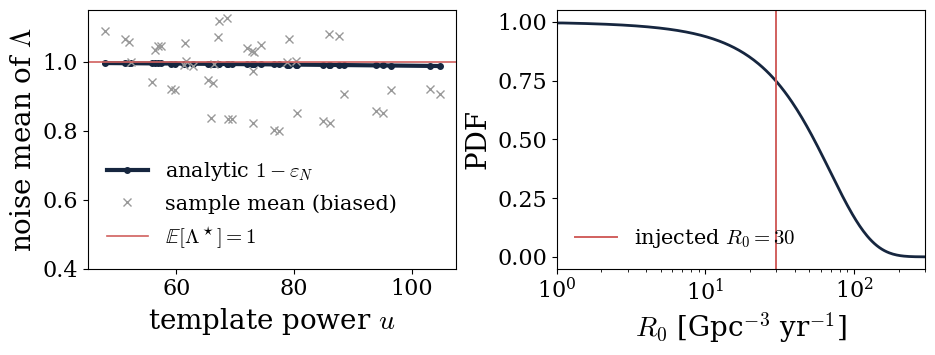

R0 90% interval from 400 segments: [3, 117]  (injected 30; a sub-threshold population needs the campaign scale, 3e4 segments, to localize - see below)


In [6]:
noise = ~is_sig.astype(bool)
C_analytic = 1.0 - EPS                       # true noise mean of Lambda = 1 - eps_N
samp_L  = np.exp(lam[noise]).mean(0)         # sample mean (heavy-tail biased, low at high u)
print('template-averaged noise mean:')
print('  analytic  E[Lambda] = %.3f   E[Lambda*] = 1.000 (exact by construction)' % C_analytic.mean())
print('  sample    E[Lambda] = %.3f   (biased LOW by the heavy tail; not a valid test)' % samp_L.mean())
S_star = np.exp(lam_star).mean(1)
R0=np.concatenate([[1e-3],np.geomspace(1.0,300.0,300)]); nbar=R0*VOL*T_SEG/YR
lnP=-S_star.size*nbar+np.log1p(nbar[:,None]*S_star[None,:]).sum(1); lnP-=lnP.max()
p_star=np.exp(lnP); p_star/=np.trapezoid(p_star,R0)
fig,(a1,a2)=plt.subplots(1,2,figsize=(9.6,3.8))
order=np.argsort(U_GRID)
a1.plot(U_GRID[order], C_analytic[order],'o-',color=NAVY,ms=4,label=r'analytic $1-\varepsilon_N$')
a1.plot(U_GRID[order], samp_L[order],'x',color='0.6',label='sample mean (biased)')
a1.axhline(1,color=RED,lw=1.2,label=r'$\mathbb{E}[\Lambda^\star]=1$')
a1.set_ylim(0.4,1.15); a1.set_xlabel(r'template power $u$'); a1.set_ylabel(r'noise mean of $\Lambda$')
a1.legend(frameon=False,fontsize=figstyle.FS_LEGEND)
a2.plot(R0,p_star/p_star.max(),color=NAVY,lw=2.0)
a2.axvline(R0_TRUE,color=RED,lw=1.4,label=r'injected $R_0=30$')
a2.set_xscale('log'); a2.set_xlim(1,300); a2.set_xlabel(r'$R_0$ [Gpc$^{-3}$ yr$^{-1}$]'); a2.set_ylabel('PDF')
a2.legend(frameon=False,fontsize=figstyle.FS_LEGEND)
fig.tight_layout(); plt.show()
cw=np.cumsum(p_star*np.gradient(R0)); cw/=cw[-1]
lo,hi=np.interp([0.05,0.95],cw,R0)
print('R0 90%% interval from 400 segments: [%.0f, %.0f]  (injected 30; a sub-threshold'
      ' population needs the campaign scale, 3e4 segments, to localize - see below)' % (lo,hi))
np.savez('data/sgwb_live.npz', u=U_GRID, eps=EPS, C_analytic=C_analytic, samp_L=samp_L,
         R0=R0, p_star=p_star)

## Paper figures

The population figures of the paper come from the cluster campaigns (`scripts/sgwb/`); we load their saved data and re-draw them.

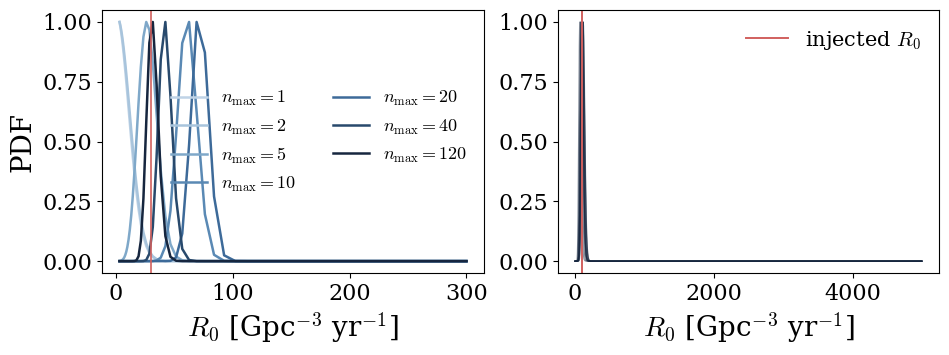

left: depth ladder (paper Fig, sgwb_depths); right: 12 rate realizations, coverage 1.00


In [7]:
FIGD = ROOT/'figures'
d = np.load(FIGD/'sgwb_depths.npz')
r = np.load(ROOT/'results/sgwb/receipts/r0_realizations.npz')
fig,(a1,a2)=plt.subplots(1,2,figsize=(9.6,3.8))
cols = figstyle.LADDER7
for c,dep in zip(cols, d['depths']):
    k='d0_n%03d'%dep
    if k in d.files:
        a1.plot(d['g_r0'], d[k]/d[k].max(), color=c, lw=1.8, label=r'$n_{\max}=%d$'%dep)
a1.axvline(np.atleast_1d(d['truths'])[0], color=RED, lw=1.2)
a1.set_xlabel(r'$R_0$ [Gpc$^{-3}$ yr$^{-1}$]'); a1.set_ylabel('PDF'); a1.legend(frameon=False,fontsize=figstyle.FS_LEGEND-2,ncol=2)
for row in r['post']:
    a2.plot(r['g_r0'], row/row.max(), color=NAVY, lw=0.8, alpha=0.5)
a2.axvline(float(r['r0_true']), color=RED, lw=1.4, label=r'injected $R_0$')
a2.set_xlabel(r'$R_0$ [Gpc$^{-3}$ yr$^{-1}$]'); a2.legend(frameon=False,fontsize=figstyle.FS_LEGEND)
fig.tight_layout(); plt.show()
print('left: depth ladder (paper Fig, sgwb_depths); right: %d rate realizations, coverage %.2f' % (r['post'].shape[0], float(r['coverage'])))

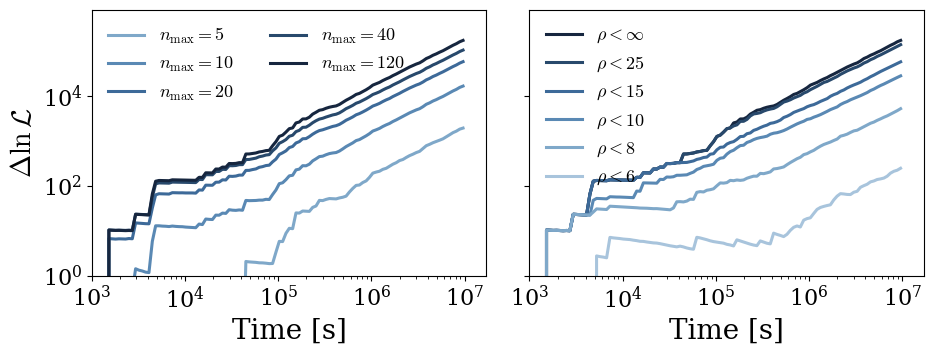

the 111-day real-observation ladder of the paper (bf_vs_time_aplus)


In [8]:
z = np.load(FIGD/'bf_vs_time_aplus.npz')
T = float(z['t_seg'])
fig,axes=plt.subplots(1,2,figsize=(9.6,3.8),sharey=True)
deps=[int(k.split('_n')[1]) for k in z.files if k.startswith('D_n')]
for c,dep in zip(figstyle.LADDER7, sorted(deps)):
    N,D = z['N_n%03d'%dep], z['D_n%03d'%dep]
    if D.max()>=1: axes[0].plot(N*T, D, color=c, lw=2.2, label=r'$n_{\max}=%d$'%dep)
cuts=[k.split('_')[-1] for k in z.files if k.startswith('D_rhocut')]
for c,cn in zip(figstyle.LADDER7[1:][::-1], cuts):
    N,D = z['N_rhocut_%s'%cn], z['D_rhocut_%s'%cn]
    lab = r'$\rho<\infty$' if cn=='inf' else r'$\rho<%d$'%int(cn)
    if D.max()>=1: axes[1].plot(N*T, D, color=c, lw=2.2, label=lab)
for ax in axes:
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_ylim(1,None); ax.set_xlim(1e3,None); ax.set_xlabel('Time [s]')
axes[0].set_ylabel(r'$\Delta\ln\mathcal{L}$')
axes[0].legend(frameon=False,fontsize=figstyle.FS_LEGEND-2,ncol=2); axes[1].legend(frameon=False,fontsize=figstyle.FS_LEGEND-2)
fig.tight_layout(); plt.show()
print('the 111-day real-observation ladder of the paper (bf_vs_time_aplus)')